In [2]:
import json
import pickle
import time
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import faiss

In [5]:
from pathlib import Path
import pickle, json

FAISS_DATA_DIR = Path("../../faiss_data")
QUERIES_PATH = Path("../../querie_data/test_queries.json")

with open(FAISS_DATA_DIR / "chunk_embeddings.pkl", "rb") as f:
    chunk_embeddings = pickle.load(f)
with open(FAISS_DATA_DIR / "chunks_by_strategy.pkl", "rb") as f:
    chunks_by_strategy = pickle.load(f)
with open(QUERIES_PATH, "r", encoding="utf-8") as f:
    queries = json.load(f)

df_queries = pd.DataFrame(queries)
assert {"id", "query", "relevant_docs"}.issubset(df_queries.columns), (
    "В test_queries.json ожидаются поля id, query, relevant_docs"
)
print("Папка эмбеддингов:", FAISS_DATA_DIR.resolve())
print("Файл запросов:", QUERIES_PATH.resolve())
print("Стратегии:", list(chunks_by_strategy))
print("Запросов:", len(df_queries))
for key, frame in chunks_by_strategy.items():
    print(f"{key}: {len(frame):,} чанков, {frame['doc_id'].nunique():,} документов")

Папка эмбеддингов: /Users/veronika_steklo/projects/ml_ssu/faiss_data
Файл запросов: /Users/veronika_steklo/projects/ml_ssu/querie_data/test_queries.json
Стратегии: ['fixed_200', 'overlap_200_50']
Запросов: 32
fixed_200: 1,557 чанков, 130 документов
overlap_200_50: 2,020 чанков, 130 документов


In [ ]:
TOP_K = 10
CANDIDATE_K = 100

from sentence_transformers import SentenceTransformer

models_config = {
    "MiniLM": {
        "name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "query_prefix": "",
        "document_prefix": ""
    },
    "MPNet": {
        "name": "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
        "query_prefix": "",
        "document_prefix": ""
    },
    "Multilingual-E5": {
        "name": "intfloat/multilingual-e5-base",
        "query_prefix": "query: ",
        "document_prefix": "passage: "
    }
}

query_embeddings = {}
for model_key, cfg in models_config.items():
    model = SentenceTransformer(cfg["name"])
    query_inputs = [cfg["query_prefix"] + str(x) for x in df_queries["query"].fillna("")]
    query_embeddings[model_key] = model.encode(
        query_inputs, batch_size=16, show_progress_bar=True,
        convert_to_numpy=True, normalize_embeddings=True
    ).astype("float32")
    print(model_key, query_embeddings[model_key].shape)

def exact_doc_results(embeddings, chunks_df, q_matrix, queries_df, k=10):
    """Полный перебор по всем чанкам; затем точная max-score агрегация на уровне документов."""
    rows = []
    for qi, qrow in queries_df.reset_index(drop=True).iterrows():
        scores = embeddings @ q_matrix[qi]
        tmp = chunks_df[["doc_id", "title"]].copy()
        tmp["score"] = scores
        docs = (tmp.groupby(["doc_id", "title"], as_index=False)["score"]
                .max().sort_values("score", ascending=False).head(k))
        docs["rank"] = np.arange(1, len(docs)+1)
        for _, r in docs.iterrows():
            rows.append({
                "query_id": qrow["id"], "rank": int(r["rank"]),
                "doc_id": r["doc_id"], "title": r["title"],
                "score": float(r["score"])
            })
    return pd.DataFrame(rows)

def recall_at_k(results_df, queries_df, k=10):
    vals = []
    for _, q in queries_df.iterrows():
        rel = set(q["relevant_docs"])
        got = set(results_df.loc[results_df["query_id"] == q["id"], "doc_id"].head(k))
        vals.append(len(got & rel) / len(rel) if rel else 0.0)
    return float(np.mean(vals))

def hit_rate_at_k(results_df, queries_df, k=10):
    vals = []
    for _, q in queries_df.iterrows():
        rel = set(q["relevant_docs"])
        got = set(results_df.loc[results_df["query_id"] == q["id"], "doc_id"].head(k))
        vals.append(float(bool(got & rel)))
    return float(np.mean(vals))

def mrr_at_k(results_df, queries_df, k=10):
    vals = []
    for _, q in queries_df.iterrows():
        rel = set(q["relevant_docs"])
        ranked = results_df.loc[
            results_df["query_id"] == q["id"], ["rank", "doc_id"]
        ].sort_values("rank").head(k)
        rr = next((1.0/int(r["rank"]) for _, r in ranked.iterrows()
                   if r["doc_id"] in rel), 0.0)
        vals.append(rr)
    return float(np.mean(vals))

exact_config_rows = []
exact_results_by_config = {}

for (strategy, model_key), emb in chunk_embeddings.items():
    emb = np.asarray(emb, dtype="float32")
    results = exact_doc_results(
        emb, chunks_by_strategy[strategy], query_embeddings[model_key], df_queries, TOP_K
    )
    exact_results_by_config[(strategy, model_key)] = results
    exact_config_rows.append({
        "strategy": strategy, "model": model_key, "chunks": len(emb),
        "Recall@10": recall_at_k(results, df_queries, TOP_K),
        "Hit Rate@10": hit_rate_at_k(results, df_queries, TOP_K),
        "MRR@10": mrr_at_k(results, df_queries, TOP_K)
    })

exact_metrics_df = pd.DataFrame(exact_config_rows).sort_values(
    ["Recall@10", "MRR@10"], ascending=False
)
display(exact_metrics_df.round(4))

PRIMARY_STRATEGY = exact_metrics_df.iloc[0]["strategy"]
PRIMARY_MODEL = exact_metrics_df.iloc[0]["model"]
X = np.asarray(chunk_embeddings[(PRIMARY_STRATEGY, PRIMARY_MODEL)], dtype="float32")
CHUNKS = chunks_by_strategy[PRIMARY_STRATEGY].reset_index(drop=True)
Q = query_embeddings[PRIMARY_MODEL]

print(f"Основная конфигурация: {PRIMARY_STRATEGY} + {PRIMARY_MODEL}")
print(f"Векторов: {len(X):,}; размерность: {X.shape[1]}; запросов: {len(Q)}")


/Users/veronika_steklo/projects/ml_ssu/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 2/2 [00:00<00:00, 10.12it/s]


MiniLM (32, 384)


Batches: 100%|██████████| 2/2 [00:00<00:00, 20.80it/s]


MPNet (32, 768)


Batches: 100%|██████████| 2/2 [00:00<00:00, 19.28it/s]


Multilingual-E5 (32, 768)


,strategy,model,chunks,Recall@10,Hit Rate@10,MRR@10
5,overlap_200_50,Multilingual-E5,2020,0.9688,0.9688,0.6730
2,fixed_200,Multilingual-E5,1557,0.9375,0.9375,0.6271
1,fixed_200,MPNet,1557,0.9375,0.9375,0.4791
4,overlap_200_50,MPNet,2020,0.8750,0.8750,0.4553
0,fixed_200,MiniLM,1557,0.8438,0.8438,0.5472
3,overlap_200_50,MiniLM,2020,0.8438,0.8438,0.4490


Основная конфигурация: overlap_200_50 + Multilingual-E5
Векторов: 2,020; размерность: 768; запросов: 32


## Эталонный поиск и метрика ANN

`IndexFlatIP` выполняет полный перебор по всем векторам и служит точным эталоном. Для оценки ANN сравниваем top-10 документов каждого приближённого метода с top-10 эталона для того же запроса. Отдельно считаем совпадение с ручной разметкой — эти две метрики отвечают на разные вопросы.

In [ ]:
def recall_at_k_against_exact(ann_results, exact_results, queries_df, k=10):
    values = []
    for _, qrow in queries_df.iterrows():
        qid = qrow["id"]
        exact_docs = set(exact_results.loc[
            exact_results["query_id"] == qid
        ].sort_values("rank")["doc_id"].head(k))
        ann_docs = set(ann_results.loc[
            ann_results["query_id"] == qid
        ].sort_values("rank")["doc_id"].head(k))
        values.append(len(ann_docs & exact_docs) / max(1, len(exact_docs)))
    return float(np.mean(values))

exact_reference_results = exact_results_by_config[(PRIMARY_STRATEGY, PRIMARY_MODEL)].copy()
print("Размер эталонного списка:", len(exact_reference_results))

Размер эталонного списка: 320


In [8]:
def build_flat(x):
    idx = faiss.IndexFlatIP(x.shape[1])
    t0 = time.perf_counter()
    idx.add(x)
    return idx, time.perf_counter() - t0

def search_index(index, q, k=CANDIDATE_K):
    t0 = time.perf_counter()
    D, I = index.search(q, min(k, index.ntotal))
    return D, I, time.perf_counter() - t0

def chunk_results_from_ids(D, I, chunks_df, queries_df, k=TOP_K):
    """Агрегирует top-к кандидатов-чанков в top-k документов."""
    rows = []
    for qi, qrow in queries_df.reset_index(drop=True).iterrows():
        tmp = []
        for rank0, (score, idx) in enumerate(zip(D[qi], I[qi]), start=1):
            if idx < 0:
                continue
            tmp.append({
                "query_id": qrow["id"], "rank_chunk": rank0,
                "doc_id": chunks_df.iloc[idx]["doc_id"],
                "title": chunks_df.iloc[idx]["title"],
                "chunk_id": chunks_df.iloc[idx]["chunk_id"],
                "score": float(score)
            })
        tmp_df = pd.DataFrame(tmp)
        if tmp_df.empty:
            continue
        docs = (tmp_df.groupby(["doc_id", "title"], as_index=False)["score"]
                .max().sort_values("score", ascending=False).head(k))
        docs["rank"] = np.arange(1, len(docs)+1)
        for _, r in docs.iterrows():
            rows.append({
                "query_id": qrow["id"], "rank": int(r["rank"]),
                "doc_id": r["doc_id"], "title": r["title"],
                "score": float(r["score"])
            })
    return pd.DataFrame(rows)

flat, flat_build = build_flat(X)
D_flat, I_flat, flat_search_time = search_index(flat, Q, CANDIDATE_K)
flat_results = chunk_results_from_ids(D_flat, I_flat, CHUNKS, df_queries, TOP_K)

flat_metrics = {
    "index": "IndexFlatIP", "parameter": "exact",
    "build_time_sec": flat_build,
    "search_time_sec": flat_search_time,
    "search_ms_per_query": 1000 * flat_search_time / len(Q),
    "Recall@10_vs_exact": 1.0,
    "Recall@10_manual": recall_at_k(flat_results, df_queries, TOP_K)
}
display(pd.DataFrame([flat_metrics]).round(4))


,index,parameter,build_time_sec,search_time_sec,search_ms_per_query,Recall@10_vs_exact,Recall@10_manual
0,IndexFlatIP,exact,0.0007,0.0052,0.164,1.0,0.9688


In [9]:
def build_hnsw(x, M=32, ef_construction=100):
    idx = faiss.IndexHNSWFlat(x.shape[1], M, faiss.METRIC_INNER_PRODUCT)
    idx.hnsw.efConstruction = ef_construction
    t0 = time.perf_counter()
    idx.add(x)
    return idx, time.perf_counter() - t0

hnsw, hnsw_build = build_hnsw(X, M=32, ef_construction=100)

hnsw_rows = []
for ef in [8, 16, 32, 64, 96, 128, 192]:
    hnsw.hnsw.efSearch = ef
    D, I, t = search_index(hnsw, Q, CANDIDATE_K)
    res = chunk_results_from_ids(D, I, CHUNKS, df_queries, TOP_K)
    hnsw_rows.append({
        "index": "HNSW",
        "efSearch": ef,
        "build_time_sec": hnsw_build,
        "search_time_sec": t,
        "search_ms_per_query": 1000*t/len(Q),
        "Recall@10": recall_at_k_against_exact(
            res, exact_reference_results, df_queries, TOP_K
        ),
        "Recall@10_manual": recall_at_k(res, df_queries, TOP_K),
        "Hit Rate@10": hit_rate_at_k(res, df_queries, TOP_K),
        "MRR@10": mrr_at_k(res, df_queries, TOP_K)
    })

hnsw_df = pd.DataFrame(hnsw_rows)
display(hnsw_df.round(4))

target = 0.95
target_rows = hnsw_df[hnsw_df["Recall@10"] >= target]
if len(target_rows):
    print("Минимальный исследованный efSearch с Recall@10 >= 0.95:",
          int(target_rows.iloc[0]["efSearch"]))
else:
    print("На исследованном диапазоне Recall@10 >= 0.95 не достигнут.")


,index,efSearch,build_time_sec,search_time_sec,search_ms_per_query,Recall@10,Recall@10_manual,Hit Rate@10,MRR@10
0,HNSW,8,0.1219,0.0003,0.0099,0.7125,0.8438,0.8438,0.5453
1,HNSW,16,0.1219,0.0003,0.0107,0.7656,0.8750,0.8750,0.5542
2,HNSW,32,0.1219,0.0004,0.0131,0.8219,0.9375,0.9375,0.6141
3,HNSW,64,0.1219,0.0006,0.0194,0.9281,0.9375,0.9375,0.6193
4,HNSW,96,0.1219,0.0006,0.0176,0.9688,0.9375,0.9375,0.6417
5,HNSW,128,0.1219,0.0008,0.0246,0.9781,0.9375,0.9375,0.6417
6,HNSW,192,0.1219,0.0011,0.0332,0.9844,0.9688,0.9688,0.6730


Минимальный исследованный efSearch с Recall@10 >= 0.95: 96


In [10]:
def choose_nlist(n):
    return max(4, min(64, int(round(math.sqrt(n)))))

def build_ivfflat(x, nlist=None):
    d = x.shape[1]
    n = len(x)
    nlist = nlist or choose_nlist(n)
    quantizer = faiss.IndexFlatIP(d)
    idx = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_INNER_PRODUCT)
    train_n = min(n, max(1000, 20*nlist))
    rng = np.random.default_rng(42)
    train_idx = rng.choice(n, size=train_n, replace=False) if train_n < n else np.arange(n)
    t0 = time.perf_counter()
    idx.train(x[train_idx])
    idx.add(x)
    return idx, time.perf_counter() - t0, nlist

ivf, ivf_build, nlist = build_ivfflat(X)

ivf_rows = []
for nprobe in sorted(set([1, max(1,nlist//8), max(1,nlist//4),
                          max(1,nlist//2), nlist])):
    ivf.nprobe = min(nprobe, nlist)
    D, I, t = search_index(ivf, Q, CANDIDATE_K)
    res = chunk_results_from_ids(D, I, CHUNKS, df_queries, TOP_K)
    ivf_rows.append({
        "index": "IVFFlat",
        "nlist": nlist,
        "nprobe": min(nprobe, nlist),
        "build_time_sec": ivf_build,
        "search_time_sec": t,
        "search_ms_per_query": 1000*t/len(Q),
        "Recall@10": recall_at_k_against_exact(
            res, exact_reference_results, df_queries, TOP_K
        ),
        "Recall@10_manual": recall_at_k(res, df_queries, TOP_K),
        "Hit Rate@10": hit_rate_at_k(res, df_queries, TOP_K),
        "MRR@10": mrr_at_k(res, df_queries, TOP_K)
    })

ivf_df = pd.DataFrame(ivf_rows)
display(ivf_df.round(4))


WARNING clustering 1000 points to 45 centroids: please provide at least 1755 training points


,index,nlist,nprobe,build_time_sec,search_time_sec,search_ms_per_query,Recall@10,Recall@10_manual,Hit Rate@10,MRR@10
0,IVFFlat,45,1,0.009,0.0003,0.0084,0.3625,0.5938,0.5938,0.3453
1,IVFFlat,45,5,0.009,0.0003,0.0094,0.7188,0.8438,0.8438,0.5617
2,IVFFlat,45,11,0.009,0.0004,0.0126,0.8781,0.9688,0.9688,0.6740
3,IVFFlat,45,22,0.009,0.0006,0.0196,0.9688,0.9688,0.9688,0.6730
4,IVFFlat,45,45,0.009,0.0010,0.0321,0.9906,0.9688,0.9688,0.6730


In [11]:
def choose_pq_m(d, preferred=16):
    divisors = [m for m in range(1, preferred+1) if d % m == 0]
    return max(divisors)

def build_ivfpq(x, nlist=None, m=None, nbits=4):
    d = x.shape[1]
    n = len(x)
    nlist = nlist or choose_nlist(n)
    m = m or choose_pq_m(d)
    quantizer = faiss.IndexFlatIP(d)
    idx = faiss.IndexIVFPQ(
        quantizer, d, nlist, m, nbits, faiss.METRIC_INNER_PRODUCT
    )
    train_n = min(n, max(1000, 40*nlist, 40*(2**nbits)))
    rng = np.random.default_rng(42)
    train_idx = rng.choice(n, size=train_n, replace=False) if train_n < n else np.arange(n)
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        idx.train(x[train_idx])
    idx.add(x)
    return idx, time.perf_counter() - t0, nlist, m, nbits

ivfpq, ivfpq_build, pq_nlist, pq_m, pq_nbits = build_ivfpq(X)

ivfpq_rows = []
for nprobe in sorted(set([1, max(1,pq_nlist//8), max(1,pq_nlist//4),
                          max(1,pq_nlist//2), pq_nlist])):
    ivfpq.nprobe = min(nprobe, pq_nlist)
    D, I, t = search_index(ivfpq, Q, CANDIDATE_K)
    res = chunk_results_from_ids(D, I, CHUNKS, df_queries, TOP_K)
    ivfpq_rows.append({
        "index": "IVFPQ",
        "nlist": pq_nlist,
        "nprobe": min(nprobe, pq_nlist),
        "M": pq_m,
        "nbits": pq_nbits,
        "build_time_sec": ivfpq_build,
        "search_time_sec": t,
        "search_ms_per_query": 1000*t/len(Q),
        "Recall@10": recall_at_k_against_exact(
            res, exact_reference_results, df_queries, TOP_K
        ),
        "Recall@10_manual": recall_at_k(res, df_queries, TOP_K),
        "Hit Rate@10": hit_rate_at_k(res, df_queries, TOP_K),
        "MRR@10": mrr_at_k(res, df_queries, TOP_K)
    })

ivfpq_df = pd.DataFrame(ivfpq_rows)
display(ivfpq_df.round(4))


,index,nlist,nprobe,M,nbits,build_time_sec,search_time_sec,search_ms_per_query,Recall@10,Recall@10_manual,Hit Rate@10,MRR@10
0,IVFPQ,45,1,16,4,0.0669,0.0002,0.0054,0.3031,0.6562,0.6562,0.3227
1,IVFPQ,45,5,16,4,0.0669,0.0002,0.0064,0.5219,0.8125,0.8125,0.4401
2,IVFPQ,45,11,16,4,0.0669,0.0003,0.0088,0.5500,0.8125,0.8125,0.4401
3,IVFPQ,45,22,16,4,0.0669,0.0003,0.0092,0.5500,0.8125,0.8125,0.4401
4,IVFPQ,45,45,16,4,0.0669,0.0004,0.0117,0.5500,0.8125,0.8125,0.4401


In [12]:
ann_summary = pd.concat([
    hnsw_df.assign(parameter=hnsw_df["efSearch"].map(lambda x: f"efSearch={x}")),
    ivf_df.assign(parameter=ivf_df["nprobe"].map(lambda x: f"nprobe={x}")),
    ivfpq_df.assign(parameter=ivfpq_df["nprobe"].map(lambda x: f"nprobe={x}"))
], ignore_index=True, sort=False)

flat_row = pd.DataFrame([{
    "index": "IndexFlatIP",
    "parameter": "exact",
    "build_time_sec": flat_metrics["build_time_sec"],
    "search_time_sec": flat_metrics["search_time_sec"],
    "search_ms_per_query": flat_metrics["search_ms_per_query"],
    "Recall@10": 1.0,
    "Recall@10_manual": flat_metrics["Recall@10_manual"],
    "Hit Rate@10": hit_rate_at_k(flat_results, df_queries, TOP_K),
    "MRR@10": mrr_at_k(flat_results, df_queries, TOP_K)
}])

summary = pd.concat([flat_row, ann_summary[
    ["index","parameter","build_time_sec","search_time_sec",
     "search_ms_per_query","Recall@10","Hit Rate@10","MRR@10"]
]], ignore_index=True)

display(summary.round(4))


,index,parameter,build_time_sec,search_time_sec,search_ms_per_query,Recall@10,Recall@10_manual,Hit Rate@10,MRR@10
0,IndexFlatIP,exact,0.0007,0.0052,0.1640,1.0000,0.9688,0.9688,0.6730
1,HNSW,efSearch=8,0.1219,0.0003,0.0099,0.7125,NaN,0.8438,0.5453
2,HNSW,efSearch=16,0.1219,0.0003,0.0107,0.7656,NaN,0.8750,0.5542
3,HNSW,efSearch=32,0.1219,0.0004,0.0131,0.8219,NaN,0.9375,0.6141
4,HNSW,efSearch=64,0.1219,0.0006,0.0194,0.9281,NaN,0.9375,0.6193
5,HNSW,efSearch=96,0.1219,0.0006,0.0176,0.9688,NaN,0.9375,0.6417
6,HNSW,efSearch=128,0.1219,0.0008,0.0246,0.9781,NaN,0.9375,0.6417
7,HNSW,efSearch=192,0.1219,0.0011,0.0332,0.9844,NaN,0.9688,0.6730
8,IVFFlat,nprobe=1,0.0090,0.0003,0.0084,0.3625,NaN,0.5938,0.3453
9,IVFFlat,nprobe=5,0.0090,0.0003,0.0094,0.7188,NaN,0.8438,0.5617


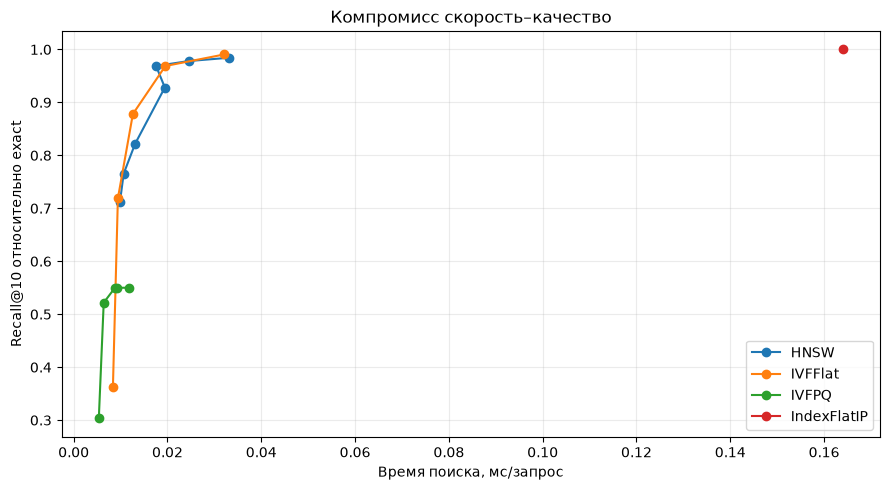

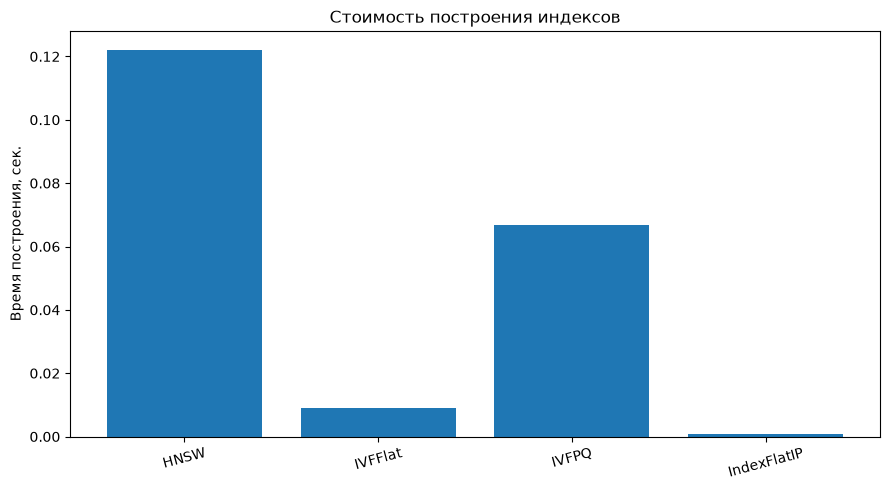

In [13]:
plt.figure(figsize=(9, 5))
for name, g in summary.groupby("index"):
    plt.plot(g["search_ms_per_query"], g["Recall@10"], marker="o", label=name)
plt.xlabel("Время поиска, мс/запрос")
plt.ylabel("Recall@10 относительно exact")
plt.title("Компромисс скорость–качество")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
build_plot = summary.groupby("index", as_index=False)["build_time_sec"].first()
plt.bar(build_plot["index"], build_plot["build_time_sec"])
plt.ylabel("Время построения, сек.")
plt.title("Стоимость построения индексов")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Анализ показательных запросов

Ниже сравниваются результаты HNSW при малом и большом `efSearch`. При просмотре таблиц обращайте внимание не только на численные оценки сходства, но и на `is_relevant`: ANN может точно воспроизводить эталон, который сам по себе не обязан совпадать с ручной разметкой. Если выдачи совпадают, но оба метода пропускают релевантный документ, проблема может быть в эмбеддингах, чанкинге или неполной разметке, а не в структуре индекса.

In [14]:
def result_table(D, I, label, parameter_value=None):
    res = chunk_results_from_ids(D, I, CHUNKS, df_queries, TOP_K)
    res = res.merge(
        df_queries[["id","query","relevant_docs"]].rename(columns={"id":"query_id"}),
        on="query_id", how="left"
    )
    res["is_relevant"] = res.apply(
        lambda r: r["doc_id"] in set(r["relevant_docs"]), axis=1
    )
    res["method"] = label
    if parameter_value is not None:
        res["parameter"] = parameter_value
    return res

hnsw_min = hnsw_df.iloc[0]["efSearch"]
hnsw_max = hnsw_df.iloc[-1]["efSearch"]

hnsw.hnsw.efSearch = int(hnsw_min)
D1, I1, _ = search_index(hnsw, Q, CANDIDATE_K)
r1 = result_table(D1, I1, "HNSW", f"efSearch={hnsw_min}")

hnsw.hnsw.efSearch = int(hnsw_max)
D2, I2, _ = search_index(hnsw, Q, CANDIDATE_K)
r2 = result_table(D2, I2, "HNSW", f"efSearch={hnsw_max}")

def per_query_recall(results):
    vals = []
    for _, q in df_queries.iterrows():
        rel = set(q["relevant_docs"])
        got = set(results.loc[results["query_id"] == q["id"], "doc_id"].head(TOP_K))
        vals.append({"query_id": q["id"], "recall": len(got & rel)/len(rel) if rel else 0})
    return pd.DataFrame(vals)

delta = per_query_recall(r2).merge(
    per_query_recall(r1), on="query_id", suffixes=("_high","_low")
)
delta["gain"] = delta["recall_high"] - delta["recall_low"]
display(delta.sort_values("gain", ascending=False).head(5))

for qid in delta.sort_values("gain", ascending=False).head(3)["query_id"]:
    q = df_queries.loc[df_queries["id"] == qid].iloc[0]
    print(f"\nЗапрос {qid}: {q['query']}")
    print("Релевантные документы:", q["relevant_docs"])
    display(r1[r1["query_id"] == qid][
        ["parameter","rank","doc_id","title","score","is_relevant"]
    ])
    display(r2[r2["query_id"] == qid][
        ["parameter","rank","doc_id","title","score","is_relevant"]
    ])


,query_id,recall_high,recall_low,gain
31,32,1.0,0.0,1.0
28,29,1.0,0.0,1.0
27,28,1.0,0.0,1.0
24,25,1.0,0.0,1.0
1,2,1.0,1.0,0.0



Запрос 32: Что в плане предлагается менять и отслеживать, чтобы уменьшить переобучение трансформера?
Релевантные документы: ['Генерация названий/Трансформер/План работы.md']


,parameter,rank,doc_id,title,score,is_relevant
310,efSearch=8,1,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.818363,False
311,efSearch=8,2,Универ/6 семестр/Машинное обучение.md,Машинное обучение,0.816565,False
312,efSearch=8,3,"Универ/экзамены, зачёты, контрольные/5 семестр...",Анализ данных,0.809823,False
313,efSearch=8,4,Универ/5 семестр/Инструменты анализа данных.md,Инструменты анализа данных,0.808935,False
314,efSearch=8,5,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО,0.802909,False
315,efSearch=8,6,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО_подробно,0.801138,False
316,efSearch=8,7,"Универ/экзамены, зачёты, контрольные/6 семестр...",мо экзамен,0.799045,False
317,efSearch=8,8,Универ/5 семестр/дз/анализ данных/12.09.md,12.09,0.793495,False
318,efSearch=8,9,Универ/6 семестр/Нейронные сети и глубокое обу...,Нейронные сети и глубокое обучение,0.789644,False
319,efSearch=8,10,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.788758,False


,parameter,rank,doc_id,title,score,is_relevant
307,efSearch=192,1,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.818363,False
308,efSearch=192,2,Универ/6 семестр/Машинное обучение.md,Машинное обучение,0.816565,False
309,efSearch=192,3,"Универ/экзамены, зачёты, контрольные/5 семестр...",Анализ данных,0.809823,False
310,efSearch=192,4,Универ/5 семестр/Инструменты анализа данных.md,Инструменты анализа данных,0.808935,False
311,efSearch=192,5,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.807762,False
312,efSearch=192,6,Универ/6 семестр/Нейронные сети и глубокое обу...,Нейронные сети и глубокое обучение,0.806317,False
313,efSearch=192,7,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО,0.805317,False
314,efSearch=192,8,Генерация названий/Трансформер/План работы.md,План работы,0.804663,True
315,efSearch=192,9,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО_подробно,0.801138,False
316,efSearch=192,10,"Универ/экзамены, зачёты, контрольные/6 семестр...",мо экзамен,0.799045,False



Запрос 29: Сколько петель набирается в кольцо для маленького зайчика и как число меняется в следующих рядах?
Релевантные документы: ['Вязание/кролики.md']


,parameter,rank,doc_id,title,score,is_relevant
280,efSearch=8,1,"Универ/экзамены, зачёты, контрольные/6 семестр...",графы экзамен,0.806448,False
281,efSearch=8,2,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.801995,False
282,efSearch=8,3,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.800823,False
283,efSearch=8,4,Универ/5 семестр/Методология разработки решени...,Методология разработки решений на основе искус...,0.798560,False
284,efSearch=8,5,Универ/5 семестр/дз/практика методология/Задач...,Задача 2. Неоднозначный PCA,0.798173,False
285,efSearch=8,6,"Универ/экзамены, зачёты, контрольные/1 семестр...",дискретная математика,0.794633,False
286,efSearch=8,7,Универ/6 семестр/Машинное обучение.md,Машинное обучение,0.794103,False
287,efSearch=8,8,Универ/6 семестр/Теория графов.md,Теория графов,0.793976,False
288,efSearch=8,9,Универ/6 семестр/Нейронные сети и глубокое обу...,Нейронные сети и глубокое обучение,0.792155,False
289,efSearch=8,10,Универ/Летняя практика/Домашнее задание.md,Домашнее задание,0.786896,False


,parameter,rank,doc_id,title,score,is_relevant
277,efSearch=192,1,Вязание/кролики.md,кролики,0.852697,True
278,efSearch=192,2,"Универ/экзамены, зачёты, контрольные/6 семестр...",графы экзамен,0.806448,False
279,efSearch=192,3,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.806108,False
280,efSearch=192,4,Универ/5 семестр/Инструменты анализа данных.md,Инструменты анализа данных,0.803722,False
281,efSearch=192,5,Универ/5 семестр/дз/практика методология/Пропу...,Пропущенный KNN,0.802323,False
282,efSearch=192,6,"Универ/экзамены, зачёты, контрольные/1 семестр...",информатика и программирование,0.801681,False
283,efSearch=192,7,"Универ/экзамены, зачёты, контрольные/6 семестр...",нейрослоп экзамен,0.801671,False
284,efSearch=192,8,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.800823,False
285,efSearch=192,9,Универ/5 семестр/Методология разработки решени...,Методология разработки решений на основе искус...,0.798560,False
286,efSearch=192,10,Универ/5 семестр/дз/практика методология/Задач...,Задача 2. Неоднозначный PCA,0.798173,False



Запрос 28: Чем короткое ухо кролика отличается от длинного по числу начальных петель?
Релевантные документы: ['Вязание/кролики.md']


,parameter,rank,doc_id,title,score,is_relevant
270,efSearch=8,1,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.784506,False
271,efSearch=8,2,Универ/6 семестр/Нейронные сети и глубокое обу...,Нейронные сети и глубокое обучение,0.775641,False
272,efSearch=8,3,Универ/5 семестр/Инструменты анализа данных.md,Инструменты анализа данных,0.773610,False
273,efSearch=8,4,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.773349,False
274,efSearch=8,5,"Универ/экзамены, зачёты, контрольные/6 семестр...",нейрослоп экзамен,0.773279,False
275,efSearch=8,6,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО,0.771002,False
276,efSearch=8,7,Универ/4 семестр/Тервер.md,Тервер,0.770730,False
277,efSearch=8,8,Универ/6 семестр/Машинное обучение.md,Машинное обучение,0.768414,False
278,efSearch=8,9,Универ/6 семестр/Теория графов.md,Теория графов,0.765521,False
279,efSearch=8,10,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО_подробно,0.762831,False


,parameter,rank,doc_id,title,score,is_relevant
267,efSearch=192,1,Вязание/кролики.md,кролики,0.813903,True
268,efSearch=192,2,"Универ/экзамены, зачёты, контрольные/6 семестр...",Машинное обучение,0.790928,False
269,efSearch=192,3,"Универ/экзамены, зачёты, контрольные/6 семестр...",Нейронные_сети_и_глубокое_обучение,0.784506,False
270,efSearch=192,4,Универ/5 семестр/Инструменты анализа данных.md,Инструменты анализа данных,0.784227,False
271,efSearch=192,5,Универ/6 семестр/Теория графов.md,Теория графов,0.783559,False
272,efSearch=192,6,Универ/6 семестр/Машинное обучение.md,Машинное обучение,0.782535,False
273,efSearch=192,7,"Универ/экзамены, зачёты, контрольные/6 семестр...",Ответы_к_экзамену_МО_подробно,0.779926,False
274,efSearch=192,8,Универ/6 семестр/Нейронные сети и глубокое обу...,Нейронные сети и глубокое обучение,0.778907,False
275,efSearch=192,9,Универ/7 семестр/Интеллектуальные системы подд...,Интеллектуальные системы поддержки принятия ре...,0.775954,False
276,efSearch=192,10,"Универ/экзамены, зачёты, контрольные/6 семестр...",мо экзамен,0.774245,False


## Стоимость построения и точка безубыточности

Точка безубыточности оценивается как `build_time / (flat_time_per_query - ann_time_per_query)`. Она имеет смысл только когда ANN быстрее точного поиска; иначе индекс в данном эксперименте не окупается по времени. Время построения считается разовым, а время поиска — для пакетного набора тестовых запросов, поэтому это приближённая оценка.

In [15]:
flat_per_query = flat_search_time / len(Q)

cost_rows = []
for method_df in [hnsw_df, ivf_df, ivfpq_df]:
    for _, r in method_df.iterrows():
        ann_per_query = r["search_time_sec"] / len(Q)
        denom = flat_per_query - ann_per_query
        breakeven = (r["build_time_sec"] / denom) if denom > 0 else np.inf
        cost_rows.append({
            "index": r["index"],
            "parameter": (
                f"efSearch={int(r['efSearch'])}" if "efSearch" in r
                else f"nprobe={int(r['nprobe'])}"
            ),
            "build_sec": r["build_time_sec"],
            "ann_ms_query": 1000*ann_per_query,
            "flat_ms_query": 1000*flat_per_query,
            "break_even_queries": breakeven,
            "Recall@10": r["Recall@10"]
        })

break_even_df = pd.DataFrame(cost_rows)
display(break_even_df.replace({np.inf: np.nan}).round(3))


,index,parameter,build_sec,ann_ms_query,flat_ms_query,break_even_queries,Recall@10
0,HNSW,efSearch=8,0.122,0.010,0.164,791.189,0.712
1,HNSW,efSearch=16,0.122,0.011,0.164,795.301,0.766
2,HNSW,efSearch=32,0.122,0.013,0.164,808.128,0.822
3,HNSW,efSearch=64,0.122,0.019,0.164,843.565,0.928
4,HNSW,efSearch=96,0.122,0.018,0.164,832.792,0.969
5,HNSW,efSearch=128,0.122,0.025,0.164,874.540,0.978
6,HNSW,efSearch=192,0.122,0.033,0.164,932.345,0.984
7,IVFFlat,nprobe=1,0.009,0.008,0.164,57.820,0.362
8,IVFFlat,nprobe=5,0.009,0.009,0.164,58.216,0.719
9,IVFFlat,nprobe=11,0.009,0.013,0.164,59.446,0.878


## Влияние размера коллекции

Сравниваются случайные подвыборки из тех же чанков. Это контролируемый эксперимент по скорости, а не отдельная оценка качества на каждом размере: случайная подвыборка может удалить документы, релевантные конкретным запросам. Поэтому значения скорости информативны, а качество на подвыборках не следует трактовать как полноценный benchmark релевантности.

WARNING clustering 505 points to 22 centroids: please provide at least 858 training points
WARNING clustering 1000 points to 32 centroids: please provide at least 1248 training points
WARNING clustering 1000 points to 45 centroids: please provide at least 1755 training points


,N,index,build_sec,search_ms_query
0,505,IndexFlatIP,0.0000,0.0163
1,505,HNSW,0.0221,0.0139
2,505,IVFFlat,0.0029,0.0059
3,1010,IndexFlatIP,0.0000,0.0147
4,1010,HNSW,0.0462,0.0144
5,1010,IVFFlat,0.0031,0.0067
6,2020,IndexFlatIP,0.0000,0.0261
7,2020,HNSW,0.1053,0.0143
8,2020,IVFFlat,0.0036,0.0127


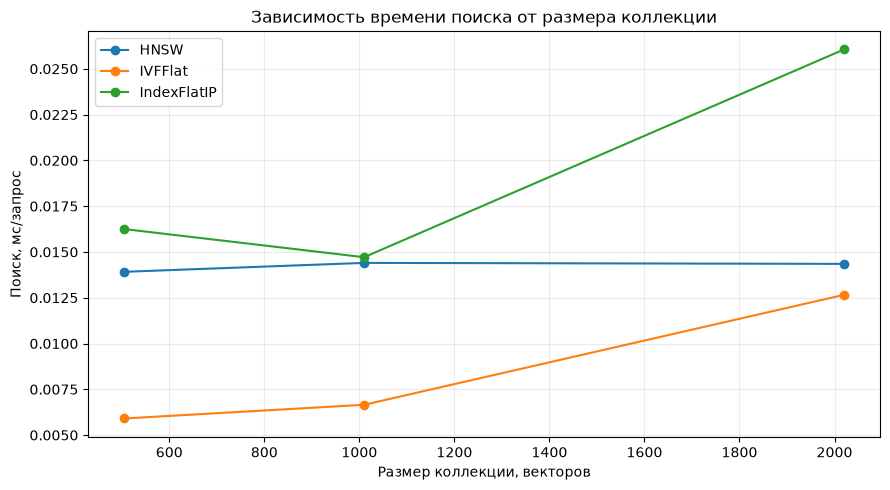

In [16]:
def make_sizes(n):
    candidates = sorted(set([
        max(1, int(n*0.25)),
        max(1, int(n*0.50)),
        n
    ]))
    if n >= 4000:
        candidates = sorted(set(candidates + [int(n*0.75)]))
    return candidates

rng = np.random.default_rng(123)
size_rows = []

for size in make_sizes(len(X)):
    if size == len(X):
        idxs = np.arange(len(X))
    else:
        idxs = rng.choice(len(X), size=size, replace=False)
    xs = X[idxs]
    chunks_s = CHUNKS.iloc[idxs].reset_index(drop=True)

    # Flat
    idx_flat, _ = build_flat(xs)
    _, _, t_flat = search_index(idx_flat, Q, CANDIDATE_K)

    # HNSW
    idx_h, bt_h = build_hnsw(xs, M=32, ef_construction=100)
    idx_h.hnsw.efSearch = 64
    _, _, t_h = search_index(idx_h, Q, CANDIDATE_K)

    # IVFFlat
    idx_i, bt_i, nl = build_ivfflat(xs)
    idx_i.nprobe = min(max(1, nl//4), nl)
    _, _, t_i = search_index(idx_i, Q, CANDIDATE_K)

    size_rows.extend([
        {"N": size, "index": "IndexFlatIP", "build_sec": 0,
         "search_ms_query": 1000*t_flat/len(Q)},
        {"N": size, "index": "HNSW", "build_sec": bt_h,
         "search_ms_query": 1000*t_h/len(Q)},
        {"N": size, "index": "IVFFlat", "build_sec": bt_i,
         "search_ms_query": 1000*t_i/len(Q)}
    ])

size_df = pd.DataFrame(size_rows)
display(size_df.round(4))

plt.figure(figsize=(9, 5))
for name, g in size_df.groupby("index"):
    plt.plot(g["N"], g["search_ms_query"], marker="o", label=name)
plt.xlabel("Размер коллекции, векторов")
plt.ylabel("Поиск, мс/запрос")
plt.title("Зависимость времени поиска от размера коллекции")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## Добавление и изменение векторов

В FAISS `add()` обычно позволяет дописать векторы в HNSW и IVF-индексы; для IVF новые векторы назначаются в уже обученные кластеры. Это не означает, что индекс сам переобучается или обновляет существующие векторы. Для замены/удаления поддержка зависит от типа индекса и обёртки; надёжная универсальная стратегия для изменения векторов — пересобрать индекс и согласованно обновить таблицу метаданных. IVFPQ также сохраняет кодированные приближения и не меняет коды старых векторов автоматически. В рабочей системе это важно при обновлении документации: устаревшие векторы не должны оставаться в поиске, а идентификаторы чанков должны совпадать с позициями в индексе.

In [ ]:
extra = X[:min(5, len(X))].copy()

for name, idx in [
    ("HNSW", hnsw),
    ("IVFFlat", ivf),
    ("IVFPQ", ivfpq),
]:
    before = idx.ntotal
    try:
        idx.add(extra)
        after = idx.ntotal
        print(f"{name}: add() успешно, {before} -> {after}")
    except Exception as e:
        print(f"{name}: add() не выполнен: {type(e).__name__}: {e}")


HNSW: add() успешно, 2020 -> 2025
IVFFlat: add() успешно, 2020 -> 2025
IVFPQ: add() успешно, 2020 -> 2025


In [ ]:
embedding_dims = []
for (strategy, model_key), emb in chunk_embeddings.items():
    embedding_dims.append({
        "strategy": strategy,
        "model": model_key,
        "dimension": emb.shape[1],
        "vectors": len(emb)
    })
display(pd.DataFrame(embedding_dims).drop_duplicates().reset_index(drop=True))


,strategy,model,dimension,vectors
0,fixed_200,MiniLM,384,1557
1,fixed_200,MPNet,768,1557
2,fixed_200,Multilingual-E5,768,1557
3,overlap_200_50,MiniLM,384,2020
4,overlap_200_50,MPNet,768,2020
5,overlap_200_50,Multilingual-E5,768,2020


In [19]:
TARGET_RECALL = 0.95

candidates = summary[
    (summary["index"] != "IndexFlatIP") &
    (summary["Recall@10"] >= TARGET_RECALL) &
    (summary["search_ms_per_query"] < flat_per_query * 1000)
].copy()

if candidates.empty:
    print("Нет ANN-конфигурации, которая одновременно достигает Recall@10 >= 0.95 "
          "и быстрее exact на данной тестовой коллекции.")
    print("Практический вывод: при текущем N и workload переход на ANN не даёт "
          "измеренного преимущества; при росте N следует повторить benchmark.")
else:
    candidates = candidates.sort_values(
        ["search_ms_per_query", "build_time_sec"]
    )
    display(candidates.head(10).round(4))
    rec = candidates.iloc[0]
    print(
        f"Конфигурация для рассмотрения: {rec['index']} / {rec['parameter']}. "
        f"Recall@10={rec['Recall@10']:.4f}, "
        f"search={rec['search_ms_per_query']:.3f} ms/query, "
        f"build={rec['build_time_sec']:.3f} s."
    )


,index,parameter,build_time_sec,search_time_sec,search_ms_per_query,Recall@10,Recall@10_manual,Hit Rate@10,MRR@10
5,HNSW,efSearch=96,0.1219,0.0006,0.0176,0.9688,NaN,0.9375,0.6417
11,IVFFlat,nprobe=22,0.0090,0.0006,0.0196,0.9688,NaN,0.9688,0.6730
6,HNSW,efSearch=128,0.1219,0.0008,0.0246,0.9781,NaN,0.9375,0.6417
12,IVFFlat,nprobe=45,0.0090,0.0010,0.0321,0.9906,NaN,0.9688,0.6730
7,HNSW,efSearch=192,0.1219,0.0011,0.0332,0.9844,NaN,0.9688,0.6730


Конфигурация для рассмотрения: HNSW / efSearch=96. Recall@10=0.9688, search=0.018 ms/query, build=0.122 s.


In [ ]:

from pathlib import Path
import json
import pickle
import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("../../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

tables = {
    "exact_metrics": globals().get("exact_metrics_df"),
    "flat_results": globals().get("flat_results"),
    "hnsw_results": globals().get("hnsw_df"),
    "ivfflat_results": globals().get("ivf_df"),
    "ivfpq_results": globals().get("ivfpq_df"),
    "summary": globals().get("summary"),
    "break_even": globals().get("break_even_df"),
    "collection_sizes": globals().get("size_df"),
    "embedding_dimensions": globals().get("embedding_dims"),
}

for name, obj in tables.items():
    if obj is not None:
        df = obj if isinstance(obj, pd.DataFrame) else pd.DataFrame(obj)
        df.to_csv(RESULTS_DIR / f"{name}.csv", index=False)

indexes = {
    "hnsw": hnsw,
    "ivfflat": ivf,
    "ivfpq": ivfpq,
    "exact_flat": flat,
}

for name, index in indexes.items():
    faiss.write_index(index, str(RESULTS_DIR / f"{name}.faiss"))

np.save(RESULTS_DIR / "document_embeddings.npy", X)
np.save(RESULTS_DIR / "query_embeddings.npy", Q)

CHUNKS.to_csv(RESULTS_DIR / "chunks_metadata.csv", index=False)
df_queries.to_json(
    RESULTS_DIR / "test_queries.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

with open(RESULTS_DIR / "experiment_data.pkl", "wb") as f:
    pickle.dump({
        "primary_strategy": PRIMARY_STRATEGY,
        "primary_model": PRIMARY_MODEL,
        "chunk_embeddings": chunk_embeddings,
        "chunks_by_strategy": chunks_by_strategy,
        "exact_reference_results": exact_reference_results,
    }, f)

for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        RESULTS_DIR / f"plot_{i:02d}.png",
        dpi=160,
        bbox_inches="tight",
    )

config = {
    "top_k": int(TOP_K),
    "primary_strategy": str(PRIMARY_STRATEGY),
    "primary_model": str(PRIMARY_MODEL),
    "collection_size": int(len(X)),
    "embedding_dimension": int(X.shape[1]),
    "query_count": int(len(Q)),
    "target_recall": 0.95,
}

with open(RESULTS_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print(f"Результаты сохранены в: {RESULTS_DIR.resolve()}")
print("Файлы:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"  {path.name} — {path.stat().st_size:,} байт")


Результаты сохранены в: /Users/veronika_steklo/projects/ml_ssu/results
Файлы:
  break_even.csv — 1,852 байт
  chunks_metadata.csv — 5,836,532 байт
  collection_sizes.csv — 478 байт
  document_embeddings.npy — 6,205,568 байт
  embedding_dimensions.csv — 220 байт
  exact_flat.faiss — 6,205,485 байт
  exact_metrics.csv — 417 байт
  experiment_config.json — 198 байт
  experiment_data.pkl — 37,275,752 байт
  flat_results.csv — 52,149 байт
  hnsw.faiss — 6,771,150 байт
  hnsw_results.csv — 913 байт
  ivfflat.faiss — 6,375,739 байт
  ivfflat_results.csv — 726 байт
  ivfpq.faiss — 220,332 байт
  ivfpq_results.csv — 732 байт
  query_embeddings.npy — 98,432 байт
  summary.csv — 2,220 байт
  test_queries.json — 9,951 байт
